# Which Loans Are Worth Funding? A Credit Risk and Profitability Analysis

**Author:** Tejas Sharma

**The question.** A lender has to decide two things for every applicant: will this person pay us back, and
if some people don't, is the interest we earn from everyone else enough to cover the losses? This project
answers that question on real data.

**The data.** About 164,000 completed personal loans from Lending Club, a US peer-to-peer lender, with
the borrower's details at application and whether the loan went bad (charged off or defaulted).

**The approach.**
1. Explore the data with SQL to see which borrower and loan features go with higher default rates.
2. Build a logistic regression model that estimates each loan's probability of default (PD).
3. Turn each PD into an expected profit, using the interest rate, a funding cost and a loss given default (LGD).
4. Compare two lending policies on loans the model has never seen: fund every loan, or fund only
   the loans with positive expected profit.

In [1]:
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Chart style: one blue for bars, light grid, plain background
BLUE, INK, GREY = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d0d0cc",
    "axes.labelcolor": INK, "xtick.color": GREY, "ytick.color": GREY, "axes.grid": True,
    "grid.color": "#e6e6e2", "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.axisbelow": True, "axes.titlesize": 12, "axes.titleweight": "bold",
})
pd.set_option("display.float_format", "{:,.3f}".format)

## 1. Load and clean the data

In [2]:
URL = "https://raw.githubusercontent.com/h2oai/app-consumer-loan/master/data/loan.csv"
loans = pd.read_csv(URL)
print(f"{len(loans):,} loans, {loans.shape[1]} columns")
loans.head()

163,987 loans, 15 columns


,loan_amnt,term,int_rate,emp_length,home_ownership,annual_inc,purpose,addr_state,dti,delinq_2yrs,revol_util,total_acc,bad_loan,longest_credit_length,verification_status
0,5000,36 months,10.650,10.000,RENT,"24,000.000",credit_card,AZ,27.650,0.000,83.700,9.000,0,26.000,verified
1,2500,60 months,15.270,0.000,RENT,"30,000.000",car,GA,1.000,0.000,9.400,4.000,1,12.000,verified
2,2400,36 months,15.960,10.000,RENT,"12,252.000",small_business,IL,8.720,0.000,98.500,10.000,0,10.000,not verified
3,10000,36 months,13.490,10.000,RENT,"49,200.000",other,CA,20.000,0.000,21.000,37.000,0,15.000,verified
4,5000,36 months,7.900,3.000,RENT,"36,000.000",wedding,AZ,11.200,0.000,28.300,12.000,0,7.000,verified


**Columns used.** `loan_amnt` (amount borrowed, USD), `term` (36 or 60 months), `int_rate` (annual interest rate, %),
`emp_length` (years employed), `home_ownership`, `annual_inc` (USD), `purpose`, `dti` (debt-to-income ratio: monthly debt
payments as a % of monthly income), `delinq_2yrs` (missed payments in the last two years), `revol_util` (% of credit card
limits in use), `total_acc` (number of credit accounts), `longest_credit_length` (years of credit history),
`verification_status` (whether income was verified) and the outcome `bad_loan` (1 = the loan went bad).

`addr_state` (US state) is left out on purpose: lending decisions should depend on the borrower's finances, not where they live.

In [3]:
# How many values are missing in each column?
loans.isna().sum()

loan_amnt                   0
term                        0
int_rate                    0
emp_length               5804
home_ownership              0
annual_inc                  4
purpose                     0
addr_state                  0
dti                         0
delinq_2yrs                29
revol_util                193
total_acc                  29
bad_loan                    0
longest_credit_length      29
verification_status         0
dtype: int64

In [4]:
df = loans.copy()

# A few hundred rows are missing core credit data, so drop them (well under 1% of the data)
df = df.dropna(subset=["annual_inc", "delinq_2yrs", "total_acc", "longest_credit_length", "revol_util"])

# About 3.5% are missing employment length: fill with the median instead of losing those rows
df["emp_length"] = df["emp_length"].fillna(df["emp_length"].median())

# Term as a number of months (36 or 60)
df["term_months"] = df["term"].str.extract(r"(\d+)").astype(int)

# Very rare home-ownership categories (ANY, NONE, OTHER: under 200 loans together) are grouped as OTHER
df["home_ownership"] = df["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})

# Two new features: how big the loan is relative to income, and income on a log scale
# (income is very skewed: a few borrowers earn millions, and logs stop them dominating the model)
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]
df["log_income"] = np.log(df["annual_inc"])

print(f"{len(df):,} loans after cleaning")
print(f"Overall bad loan rate: {df['bad_loan'].mean():.1%}")

163,794 loans after cleaning
Overall bad loan rate: 18.3%


## 2. Explore the data with SQL

The cleaned table goes into an in-memory SQLite database so it can be queried with SQL, the way analysts query
a lender's loan book. Each query returns the number of loans and the bad loan rate for each group.

In [5]:
db = sqlite3.connect(":memory:")
df.to_sql("loans", db, index=False)

def sql(query):
    return pd.read_sql(query, db)

sql("""
SELECT term,
       COUNT(*)                 AS loans,
       ROUND(AVG(bad_loan), 3)  AS bad_rate
FROM loans
GROUP BY term
ORDER BY bad_rate
""")

,term,loans,bad_rate
0,36 months,129785,0.154
1,60 months,34009,0.295


60-month loans go bad almost twice as often as 36-month loans (29% vs 15%).

In [6]:
rate_bands = sql("""
SELECT CASE WHEN int_rate < 8  THEN '1. under 8%'
            WHEN int_rate < 11 THEN '2. 8-11%'
            WHEN int_rate < 14 THEN '3. 11-14%'
            WHEN int_rate < 17 THEN '4. 14-17%'
            WHEN int_rate < 20 THEN '5. 17-20%'
            ELSE '6. 20%+' END AS interest_rate,
       COUNT(*)                AS loans,
       ROUND(AVG(bad_loan), 3) AS bad_rate
FROM loans
GROUP BY interest_rate
ORDER BY interest_rate
""")
rate_bands

,interest_rate,loans,bad_rate
0,1. under 8%,21512,0.058
1,2. 8-11%,25013,0.104
2,3. 11-14%,43094,0.150
3,4. 14-17%,37231,0.214
4,5. 17-20%,23034,0.286
5,6. 20%+,13910,0.364


In [7]:
dti_bands = sql("""
SELECT CASE WHEN dti < 10 THEN '1. under 10%'
            WHEN dti < 20 THEN '2. 10-20%'
            WHEN dti < 30 THEN '3. 20-30%'
            ELSE '4. 30%+' END AS debt_to_income,
       COUNT(*)                AS loans,
       ROUND(AVG(bad_loan), 3) AS bad_rate
FROM loans
GROUP BY debt_to_income
ORDER BY debt_to_income
""")
dti_bands

,debt_to_income,loans,bad_rate
0,1. under 10%,39388,0.137
1,2. 10-20%,75069,0.172
2,3. 20-30%,43400,0.228
3,4. 30%+,5937,0.292


In [8]:
purposes = sql("""
SELECT purpose,
       COUNT(*)                AS loans,
       ROUND(AVG(bad_loan), 3) AS bad_rate
FROM loans
GROUP BY purpose
HAVING COUNT(*) >= 1000          -- only purposes with enough loans to trust the rate
ORDER BY bad_rate DESC
""")
purposes

,purpose,loans,bad_rate
0,small_business,3836,0.309
1,other,10438,0.214
2,moving,1460,0.208
3,medical,2022,0.203
4,debt_consolidation,93199,0.189
5,house,1244,0.182
6,vacation,1091,0.179
7,credit_card,30781,0.157
8,home_improvement,9858,0.156
9,wedding,1749,0.145


In [9]:
sql("""
SELECT verification_status,
       COUNT(*)                AS loans,
       ROUND(AVG(bad_loan), 3) AS bad_rate,
       ROUND(AVG(int_rate), 2) AS avg_interest_rate
FROM loans
GROUP BY verification_status
""")

,verification_status,loans,bad_rate,avg_interest_rate
0,not verified,59061,0.151,12.410
1,verified,104733,0.201,14.450


**A result worth questioning.** Borrowers whose income was *verified* default more often (20%) than unverified ones (15%).
Verification doesn't cause defaults. Lending Club tended to verify riskier applications, and those borrowers were charged
higher rates (see the average interest rate column). This is a reminder that a pattern in the data is not the same as a cause.

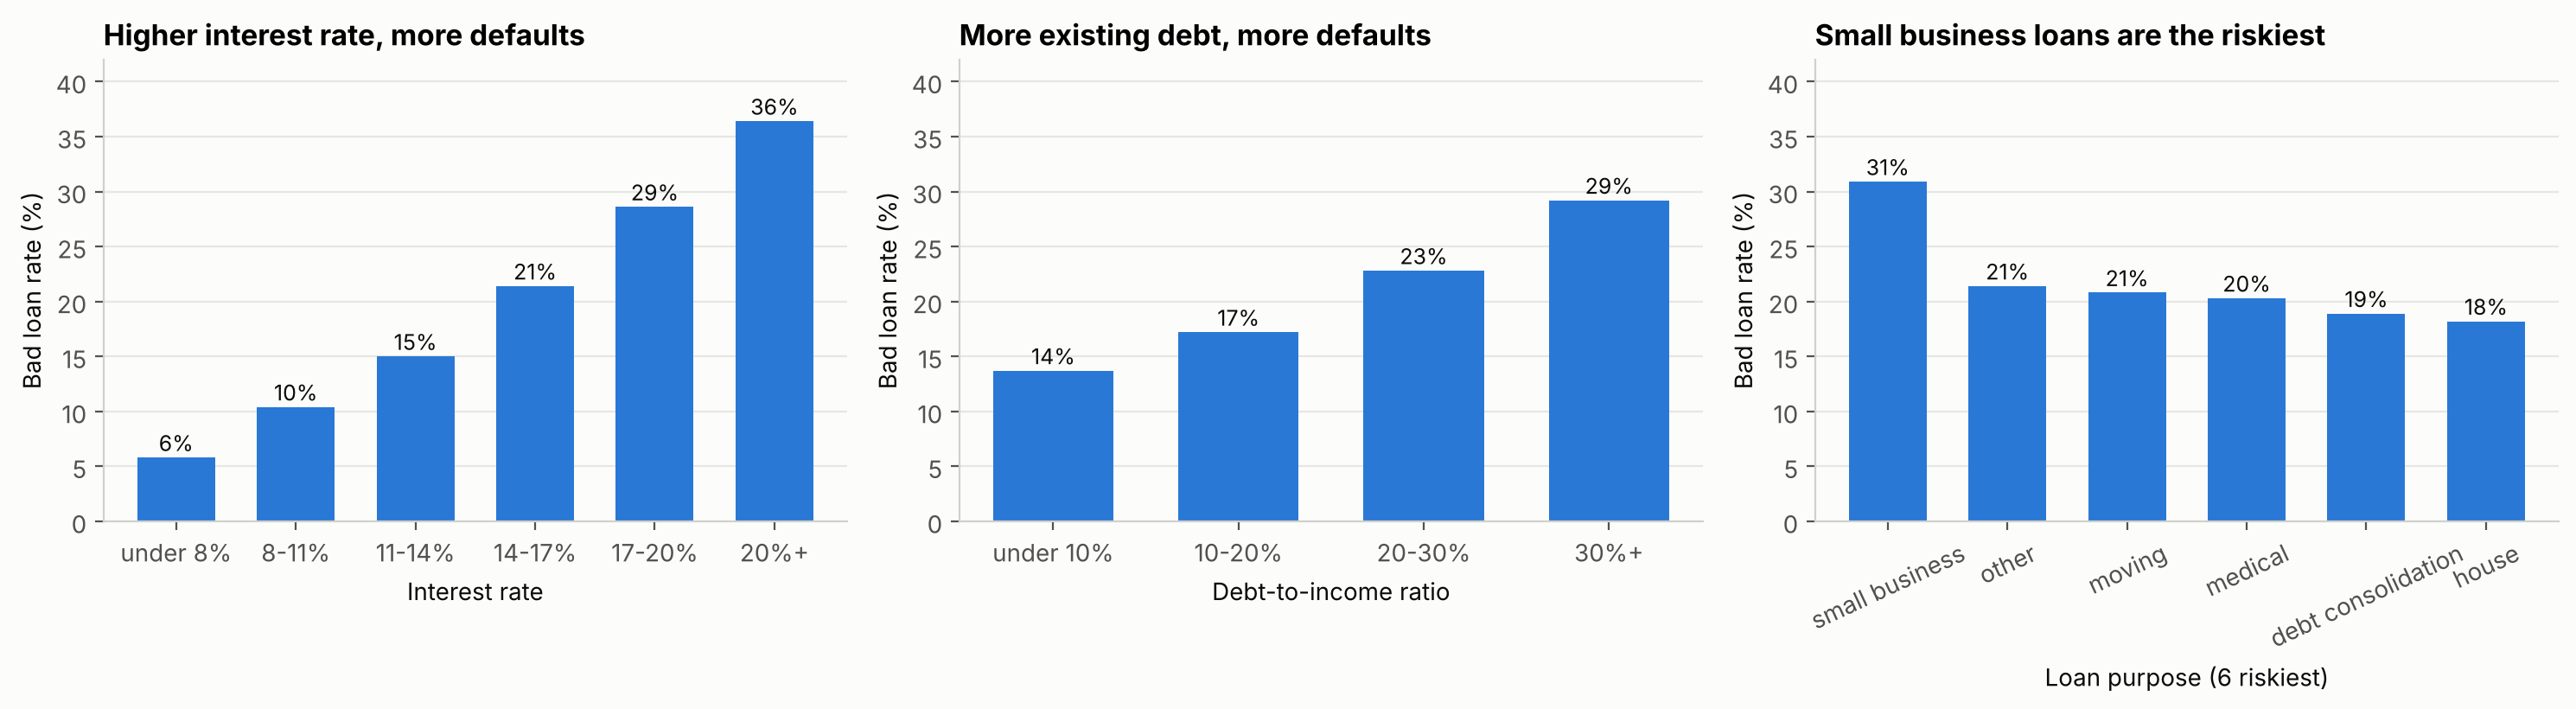

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

def bars(ax, labels, values, title, xlabel):
    ax.bar(labels, values * 100, color=BLUE, width=0.65)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Bad loan rate (%)")
    ax.grid(axis="x", visible=False)
    for i, v in enumerate(values):
        ax.text(i, v * 100 + 0.6, f"{v:.0%}", ha="center", color=INK, fontsize=9)

bars(axes[0], [b[3:] for b in rate_bands["interest_rate"]], rate_bands["bad_rate"],
     "Higher interest rate, more defaults", "Interest rate")
bars(axes[1], [b[3:] for b in dti_bands["debt_to_income"]], dti_bands["bad_rate"],
     "More existing debt, more defaults", "Debt-to-income ratio")
top = purposes.sort_values("bad_rate", ascending=False).head(6)
bars(axes[2], top["purpose"].str.replace("_", " "), top["bad_rate"],
     "Small business loans are the riskiest", "Loan purpose (6 riskiest)")
axes[2].tick_params(axis="x", rotation=25)
for ax in axes:
    ax.set_ylim(0, 42)
plt.tight_layout()
plt.show()

**What the exploration shows**
- **Price reflects risk.** The bad loan rate climbs from 6% for loans under 8% interest to 36% for loans at 20% and over.
  Lending Club's own pricing already captures a lot of the risk.
- **Existing debt matters.** Borrowers with debt-to-income over 30% default at about twice the rate of those under 10%.
- **Term and purpose matter.** 60-month loans and small business loans are much riskier.

The next question is whether the interest rate on the riskiest loans is high enough to pay for those defaults.

## 3. Model the probability of default

**Model choice: logistic regression.** It is the standard method for credit scorecards because every input has a clear,
explainable effect on the probability of default, which matters when a lender must justify its decisions to customers
and regulators.

**Fair test.** The model is trained on 70% of the loans and tested on the other 30%, which it never sees during training.

In [11]:
numeric = ["int_rate", "term_months", "emp_length", "log_income", "loan_to_income", "dti",
           "delinq_2yrs", "revol_util", "total_acc", "longest_credit_length"]
categorical = ["home_ownership", "purpose", "verification_status"]

# Turn each category into 0/1 columns (one category per group is left out as the baseline)
X = pd.get_dummies(df[numeric + categorical], columns=categorical, drop_first=True, dtype=float)
y = df["bad_loan"]

X_train, X_test, y_train, y_test, df_train, df_test = train_test_split(
    X, y, df, test_size=0.3, random_state=42, stratify=y)

# Put every input on the same scale so the coefficients can be compared with each other
scaler = StandardScaler().fit(X_train)
model = LogisticRegression(max_iter=2000).fit(scaler.transform(X_train), y_train)

pd_test = model.predict_proba(scaler.transform(X_test))[:, 1]   # probability of default for each test loan
print(f"Training loans: {len(X_train):,}   Test loans: {len(X_test):,}")

Training loans: 114,655   Test loans: 49,139


**How good is the model?** The AUC is the probability that, given one loan that went bad and one that didn't,
the model gives the bad one a higher PD. 0.5 is a coin toss and 1.0 is perfect. UK credit teams often quote the
**Gini coefficient** instead, which is just 2 × AUC − 1.

In [12]:
auc_model = roc_auc_score(y_test, pd_test)
auc_rate = roc_auc_score(y_test, df_test["int_rate"])
print(f"Model:               AUC {auc_model:.3f}   Gini {2 * auc_model - 1:.3f}")
print(f"Interest rate alone: AUC {auc_rate:.3f}   Gini {2 * auc_rate - 1:.3f}")

Model:               AUC 0.703   Gini 0.406
Interest rate alone: AUC 0.670   Gini 0.341


The model ranks risk better than the interest rate alone, so the other borrower details add information beyond
Lending Club's pricing. An AUC around 0.70 is typical for application-only consumer credit data; lenders with
credit bureau and bank account data do better.

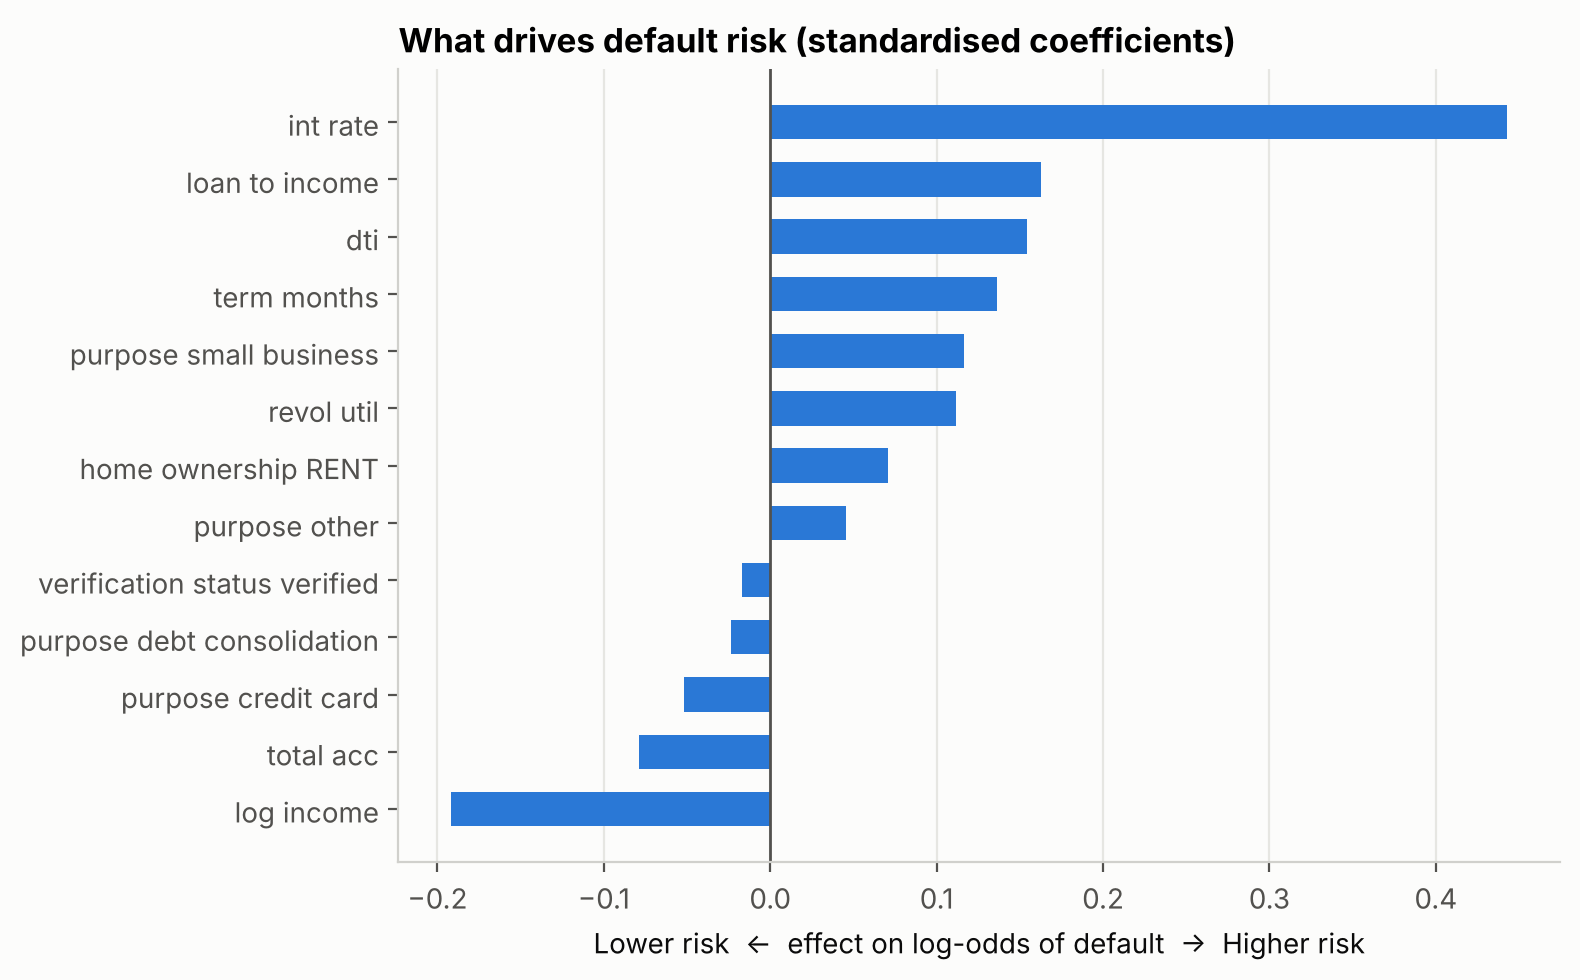

In [13]:
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
show = pd.concat([coefs.head(5), coefs.tail(8)])

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(show.index.str.replace("_", " "), show.values, color=BLUE, height=0.6)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_title("What drives default risk (standardised coefficients)", loc="left")
ax.set_xlabel("Lower risk  <-  effect on log-odds of default  ->  Higher risk")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Reading the coefficients.** Because every input was put on the same scale, a bigger bar means a bigger effect.
The interest rate is the strongest single signal, followed by loan size relative to income, debt-to-income,
loan term, small business purpose and credit card utilisation. Higher income and more credit accounts reduce risk.

Note that income verification now has a slightly *negative* coefficient, even though verified borrowers defaulted more
often in section 2. Once the model accounts for the interest rate and the borrower's finances, verification no longer
signals extra risk, which supports the explanation that Lending Club simply verified riskier applicants.

**Is the model calibrated?** For credit decisions the PD itself must be accurate, not just the ranking. The table
splits the test loans into ten equal groups by predicted PD and compares the average prediction with what actually happened.

In [14]:
test = df_test.copy()
test["pd"] = pd_test
test["pd_decile"] = pd.qcut(test["pd"], 10, labels=range(1, 11))

calibration = test.groupby("pd_decile", observed=True).agg(
    loans=("pd", "size"),
    predicted_pd=("pd", "mean"),
    actual_bad_rate=("bad_loan", "mean"),
    avg_interest_rate=("int_rate", "mean"),
)
calibration

,loans,predicted_pd,actual_bad_rate,avg_interest_rate
pd_decile,,,,
1,4914,0.052,0.044,7.875
2,4914,0.079,0.075,9.642
3,4914,0.101,0.099,11.081
4,4914,0.122,0.115,12.129
5,4914,0.144,0.148,13.076
6,4913,0.169,0.174,14.033
7,4914,0.199,0.200,14.974
8,4914,0.238,0.255,16.127
9,4914,0.295,0.307,17.471


Predicted and actual default rates line up closely in every group, from about 5% in the safest tenth to about 42%
in the riskiest, so the PDs can be used directly in a profit calculation.

## 4. From default risk to expected profit

A loan is worth making if the interest from borrowers who repay outweighs the losses from those who don't.
For each loan:

- **If it repays:** profit = total interest received − cost of funding the loan
- **If it goes bad:** loss = LGD × loan amount
- **Expected profit** = (1 − PD) × profit if repaid − PD × loss if bad

**Assumptions**
- **Cost of funds: 4% a year.** What the lender pays for the money it lends out.
- **Loss given default (LGD): 60%.** The share of the loan lost when a loan goes bad, after any repayments
  made before default and any recoveries. Tested at 40% and 80% below.
- Loans are repaid in equal monthly instalments over the term, so interest is calculated on a falling balance.

In [15]:
COST_OF_FUNDS = 0.04
LGD = 0.60

def total_interest(amount, annual_rate, months):
    """Total interest paid on an amortising loan with equal monthly payments."""
    r = annual_rate / 12
    payment = amount * r / (1 - (1 + r) ** -months)
    return payment * months - amount

test["profit_if_repaid"] = (total_interest(test["loan_amnt"], test["int_rate"] / 100, test["term_months"])
                            - total_interest(test["loan_amnt"], COST_OF_FUNDS, test["term_months"]))
test["loss_if_bad"] = LGD * test["loan_amnt"]
test["expected_profit"] = (1 - test["pd"]) * test["profit_if_repaid"] - test["pd"] * test["loss_if_bad"]

# What each loan actually earned, using the real outcome
test["actual_profit"] = np.where(test["bad_loan"] == 1, -test["loss_if_bad"], test["profit_if_repaid"])

test[["loan_amnt", "int_rate", "term_months", "pd", "profit_if_repaid", "loss_if_bad", "expected_profit"]].head()

,loan_amnt,int_rate,term_months,pd,profit_if_repaid,loss_if_bad,expected_profit
52356,4200,6.970,36,0.062,202.517,"2,520.000",33.947
7146,9000,9.990,36,0.078,887.276,"5,400.000",394.159
79598,25000,17.270,60,0.274,"9,872.193","15,000.000","3,060.678"
55723,34800,15.220,60,0.254,"11,461.125","20,880.000","3,253.795"
66334,17325,23.280,60,0.252,"10,327.487","10,395.000","5,115.627"


## 5. Does the model make better lending decisions?

Two policies are compared on the test loans, using what actually happened to each loan:
- **Fund every loan** (what Lending Club actually approved)
- **Model policy:** fund only the loans with positive expected profit

In [16]:
def portfolio(loans_funded):
    return {
        "loans funded": len(loans_funded),
        "amount lent ($m)": loans_funded["loan_amnt"].sum() / 1e6,
        "bad loan rate": loans_funded["bad_loan"].mean(),
        "actual profit ($m)": loans_funded["actual_profit"].sum() / 1e6,
        "return on amount lent": loans_funded["actual_profit"].sum() / loans_funded["loan_amnt"].sum(),
    }

approved = test[test["expected_profit"] > 0]
declined = test[test["expected_profit"] <= 0]

results = pd.DataFrame({
    "Fund every loan": portfolio(test),
    "Model policy": portfolio(approved),
    "Loans the model declines": portfolio(declined),
}).T
results

,loans funded,amount lent ($m),bad loan rate,actual profit ($m),return on amount lent
Fund every loan,"49,139.000",642.746,0.183,33.959,0.053
Model policy,"38,998.000",521.836,0.165,37.574,0.072
Loans the model declines,"10,141.000",120.910,0.253,-3.615,-0.030


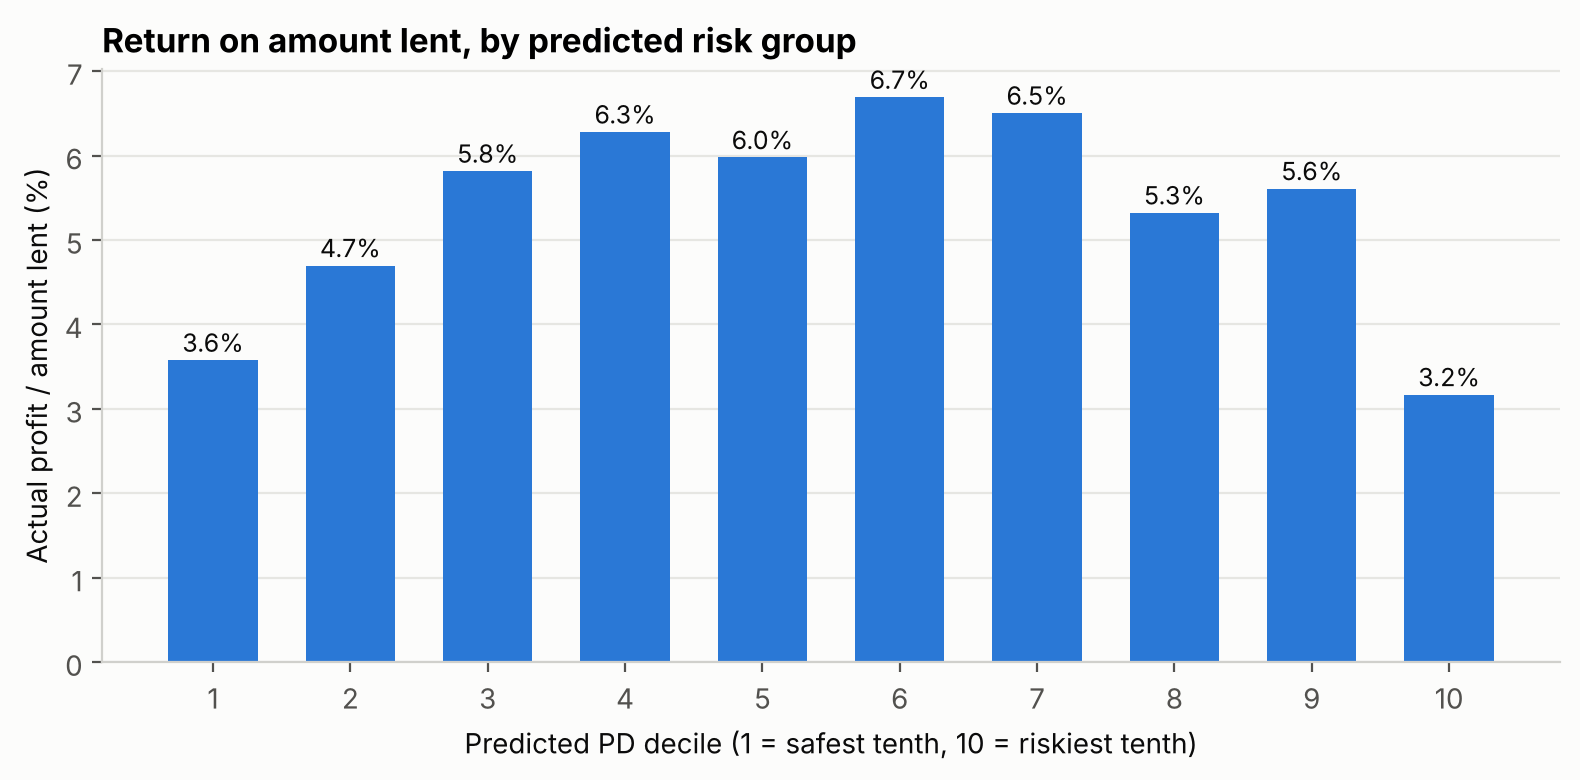

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
by_decile = test.groupby("pd_decile", observed=True)
return_by_decile = by_decile["actual_profit"].sum() / by_decile["loan_amnt"].sum() * 100
ax.bar(return_by_decile.index.astype(str), return_by_decile.values, color=BLUE, width=0.65)
for i, v in enumerate(return_by_decile.values):
    ax.text(i, v + 0.1, f"{v:.1f}%", ha="center", color=INK, fontsize=9)
ax.set_title("Return on amount lent, by predicted risk group", loc="left")
ax.set_xlabel("Predicted PD decile (1 = safest tenth, 10 = riskiest tenth)")
ax.set_ylabel("Actual profit / amount lent (%)")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

Returns rise with risk at first, because riskier borrowers pay higher rates, peak in the middle groups at around
6.5%, then fall to about 3% in the riskiest tenth, where the extra interest no longer covers the extra defaults.
Most of the loans the model declines come from the three riskiest groups. It also declines some loans in the safest
groups: these carry such low interest rates that, after the cost of funds, even a small chance of default wipes out
the expected profit. The declined loans together lost money, which is why removing them raises total profit.

**How sensitive is this to the LGD assumption?**

In [18]:
rows = []
for lgd in [0.40, 0.60, 0.80]:
    loss = lgd * test["loan_amnt"]
    exp_profit = (1 - test["pd"]) * test["profit_if_repaid"] - test["pd"] * loss
    actual = np.where(test["bad_loan"] == 1, -loss, test["profit_if_repaid"])
    keep = exp_profit > 0
    rows.append({
        "LGD": f"{lgd:.0%}",
        "share of loans funded": keep.mean(),
        "profit, fund all ($m)": actual.sum() / 1e6,
        "profit, model policy ($m)": actual[keep].sum() / 1e6,
        "extra profit ($m)": (actual[keep].sum() - actual.sum()) / 1e6,
    })
pd.DataFrame(rows).set_index("LGD")

,share of loans funded,"profit, fund all ($m)","profit, model policy ($m)",extra profit ($m)
LGD,,,,
40%,0.958,59.237,59.402,0.165
60%,0.794,33.959,37.574,3.615
80%,0.563,8.681,22.736,14.055


## 6. Findings

1. **Default risk is predictable from application data.** Interest rate, loan size relative to income, debt-to-income,
   loan term, purpose and credit card utilisation are the main drivers. The model reaches an AUC of about 0.70
   (Gini about 0.41) on unseen loans, and its predicted default rates match actual rates closely across all risk groups.
2. **The riskiest loans were underpriced.** In the riskiest tenth of loans, about 4 in 10 went bad. Even at an
   average rate of about 21%, they returned about 3% on the amount lent, against around 6.5% in the middle risk groups.
3. **Lending on expected profit beats lending to everyone.** On the test loans, funding only loans with positive
   expected profit lent to about 4 in 5 applicants, cut the bad loan rate, and earned more profit in total from less
   money lent. The extra profit gets larger as the assumed LGD rises, because avoiding bad loans matters more.

**What a lender would do next**
- Re-price the riskiest segments instead of declining them outright, then check whether demand holds at the higher rate.
- Test the policy on the most recent loans rather than a random split, to make sure it still works as the economy changes.
- Add better data, such as credit bureau scores and bank transaction data, to separate good from bad borrowers more sharply.

**Limitations**
- The profit calculation is simplified: one LGD for all loans and no operating costs. Real lenders model recoveries and
  the timing of defaults in more detail.
- Only loans Lending Club approved are in the data, so the model has never seen the applicants who were declined.
- The data has no application dates, so the split is random instead of by time.